<a href="https://colab.research.google.com/github/superco-art/Brecha_digital_wifi_Barcelona/blob/main/Proyecto_brecha_digital_wifi_barcelona.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PROYECTO: PRIMEROS PASOS DEL DATO A LA DECISIÓN - BRECHA DIGITAL Y WIFI BCN**

Presentado por Daniela Trifu

## Descripción del Dataset: Puntos Wi-Fi de Barcelona
1. **¿De qué trata el dataset?**
Este conjunto de datos proviene del portal oficial de datos abiertos del Ayuntamiento de Barcelona (Open Data BCN). Contiene el registro y la geolocalización de **los puntos de acceso a la red Wi-Fi pública** y gratuita situados en diversos equipamientos, espacios y calles de la ciudad. Su objetivo principal es facilitar la conectividad ciudadana y reducir la brecha digital.

2. **¿Qué representa cada fila?**

Cada fila (o registro) representa un punto de acceso Wi-Fi individual e independiente instalado en un equipamiento público o espacio de la ciudad (por ejemplo, un punto de conexión dentro de una biblioteca, un centro cívico o un parque).

3. **Variables principales utilizadas en el proyecto**

Este dataset es como una lista de asistencia con fichas de identificación. Estas son las variables clave que seleccionamos:

 **`register_id`(Identificador único):**

- Es el código de identidad de cada punto Wi-Fi (como el DNI del dispositivo).

- Nos permite contar cuántos puntos hay en total sin repetir ninguno (COUNT(register_id) en SQL).

**`name` / nombre_equipamiento (Nombre del lugar):**

- es el nombre del edificio o espacio donde está instalado el Wi-Fi (ej. "Biblioteca Sagrada Família" o "Centre Cívic Barceloneta").

- Nos da contexto sobre qué tipo de servicio público está ofreciendo la conexión.

**`addresses_district_name` / distrito (Distrito municipal):**

- es la gran división territorial de la ciudad a la que pertenece el punto (ej. "Eixample", "Sants-Montjuïc", "Nou Barris").

- permite agrupar los datos a nivel macro para ver qué zonas de la ciudad tienen más o menos infraestructura.

**`addresses_neighborhood_name` / barrio (Barrio municipal):**

- la subdivisión local dentro de un distrito (ej. "El Raval", "Gràcia", "Poble Sec").

- es nuestra variable clave (o puente). Nos permite cruzar (hacer un JOIN) con la información socioeconómica para analizar si los barrios con menor renta tienen suficiente acceso a internet.

### 1. Carga de librerias y Exploración Inicial del Dataset

En este primer paso, cargamos el archivo CSV descargado de Open Data BCN. [Enlace dataset](https://opendata-ajuntament.barcelona.cat/data/es/dataset/punts-wifi)
* **Reto técnico habitual:** Los archivos institucionales a menudo utilizan codificaciones de texto específicas (como UTF-16 o ISO-8859-1) o separadores distintos a la coma habitual (como el punto y coma `;`). Ajustamos los parámetros `sep` y `encoding` para asegurar una lectura correcta de los caracteres (acentos, 'ñ', etc.).

In [30]:
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


# Definimos la ruta del archivo CSV
archivo_csv = "opendatabcn_wifi.csv" # Cargamos el dataset desde https://opendata-ajuntament.barcelona.cat/data/es/dataset/punts-wifi

try:
    # Leemos el archivo asegurando el separador y la codificación adecuada
    df_wifi = pd.read_csv(archivo_csv, sep=",", encoding="utf-16") #cambiamos a UTF 16 en vez de 8 para que los datos puedan ser leidos y tambien cambiamos el ";" por "," para separar los datos
    print(" Archivo cargado con éxito.")
except Exception as e:
    print(f" Error al cargar el archivo: {str(e)}")
    df_wifi = pd.DataFrame()

# Inspeccionamos las dimensiones (filas, columnas) del dataset bruto
print(f"Dimensiones del dataset: {df_wifi.shape[0]} filas y {df_wifi.shape[1]} columnas.\n")

# Mostramos las primeras 5 filas para verificar la estructura
df_wifi.head()

 Archivo cargado con éxito.
Dimensiones del dataset: 1040 filas y 40 columnas.



,register_id,name,institution_id,institution_name,created,modified,addresses_roadtype_id,addresses_roadtype_name,addresses_road_id,addresses_road_name,...,secondary_filters_tree,secondary_filters_asia_id,geo_epgs_25831_x,geo_epgs_25831_y,geo_epgs_4326_lat,geo_epgs_4326_lon,estimated_dates,start_date,end_date,timetable
0,﻿99278103356,Espai de Gent Gran Fort Pienc,NaN,NaN,1999-10-05T00:00:00+02:00,2026-05-29T14:12:48.670183+02:00,NaN,NaN,701420.0,Plaça de Fort Pienc,...,651,65103002002000,431654.147,4582991.103,41.395552,2.182437,NaN,NaN,NaN,"<table class=""timetable-table""><tr class=""time..."
1,﻿99278103356,Espai de Gent Gran Fort Pienc,NaN,NaN,1999-10-05T00:00:00+02:00,2026-05-29T14:12:48.670183+02:00,NaN,NaN,701420.0,Plaça de Fort Pienc,...,651,65103013000000,431654.147,4582991.103,41.395552,2.182437,NaN,NaN,NaN,"<table class=""timetable-table""><tr class=""time..."
2,﻿92168175394,Centre Esportiu Municipal Trinitat Vella,NaN,NaN,1989-10-26T00:00:00+01:00,2026-07-29T08:51:31.029469+02:00,NaN,NaN,34400.0,Via de Bàrcino,...,651,65103004000000,432604.008,4589188.630,41.451452,2.193108,NaN,NaN,NaN,"<table class=""timetable-table""><tr class=""time..."
3,﻿92168175394,Centre Esportiu Municipal Trinitat Vella,NaN,NaN,1989-10-26T00:00:00+01:00,2026-07-29T08:51:31.029469+02:00,NaN,NaN,34400.0,Via de Bàrcino,...,651,65103004001009,432604.008,4589188.630,41.451452,2.193108,NaN,NaN,NaN,"<table class=""timetable-table""><tr class=""time..."
4,﻿92168175394,Centre Esportiu Municipal Trinitat Vella,NaN,NaN,1989-10-26T00:00:00+01:00,2026-07-29T08:51:31.029469+02:00,NaN,NaN,34400.0,Via de Bàrcino,...,651,65103004001003,432604.008,4589188.630,41.451452,2.193108,NaN,NaN,NaN,"<table class=""timetable-table""><tr class=""time..."


### 2. Selección y Renombrado de Variables Relevantes

Un dataset real suele contener columnas técnicas que no aportan valor a nuestro análisis específico.
1. **Selección:** Conservamos únicamente los identificadores y las variables geográficas.
2. **Renombrado:** Traducimos o simplificamos los nombres de las columnas para que el código y las consultas SQL posteriores sean legibles e intuitivas.

In [31]:
# 1. Definimos las columnas que realmente necesitamos para el análisis
columnas_interes = [
    "register_id",
    "name",
    "addresses_neighborhood_name",
    "addresses_district_name",
]

# Creamos una copia explícita del DataFrame filtrado para evitar avisos de memoria
df_limpio = df_wifi[columnas_interes].copy()

# 2. Renombramos las columnas a un castellano claro y conciso
df_limpio = df_limpio.rename(
    columns={
        "name": "nombre_equipamiento",
        "addresses_neighborhood_name": "barrio",
        "addresses_district_name": "distrito",
    }
)

# Visualizamos la estructura de las columnas resultantes
print("Columnas renombradas correctamente:")
print(df_limpio.columns.tolist())

Columnas renombradas correctamente:
['register_id', 'nombre_equipamiento', 'barrio', 'distrito']


### 3. Diagnóstico y Tratamiento de Valores Nulos

**Justificación pedagógica:**
Antes de eliminar o modificar datos faltantes, debemos preguntarnos: *¿Cómo afecta este dato nulo a nuestro objetivo?*
En este caso, si un punto Wi-Fi no tiene asignado un **barrio** o **distrito**, resulta imposible agruparlo o cruzarlo con variables socioeconómicas territoriales. Por tanto, la decisión técnica justificada es eliminar las filas donde estas variables geográficas sean nulas.

In [32]:
# Contamos cuántos valores nulos hay por cada columna antes de limpiar
nulos_iniciales = df_limpio.isnull().sum()
print("Valores nulos detectados por columna antes del filtrado:")
print(nulos_iniciales)

# Eliminamos únicamente las filas donde falte el barrio o el distrito
df_limpio = df_limpio.dropna(subset=["barrio", "distrito"])

# Verificamos cuántas filas conservamos tras la limpieza
print(f"\nFilas restantes tras eliminar registros sin localización: {len(df_limpio)}")

Valores nulos detectados por columna antes del filtrado:
register_id            0
nombre_equipamiento    0
barrio                 1
distrito               1
dtype: int64

Filas restantes tras eliminar registros sin localización: 1039


### 4. Creación de la Tabla Auxiliar Socioeconómica (para el JOIN)

Para poder analizar la brecha digital, necesitamos cruzar la presencia de Wi-Fi con el nivel socioeconómico de cada zona.
Como el dataset original solo contiene los puntos de conexión, creamos una tabla auxiliar simulada con los **barrios reales** presentes en el dataset, asignando:
* `renta_media_hogar`: Un valor estimado de ingresos.
* `nivel_vulnerabilidad`: Una clasificación cualitativa ('Alta', 'Media', 'Baja').

In [33]:
# Extraemos la lista de barrios únicos que sí existen en nuestro dataset limpio
barrios_unicos = df_limpio["barrio"].unique()

# Fijamos una semilla (seed) para que los datos aleatorios sean siempre idénticos al reejecutar
# Esto es fundamental en ciencia de datos para garantizar que los resultados no cambien por sorpresa.
# Al fijar una semilla (en este caso con el número 42), le estás diciendo a Python: "Quiero que simules azar, pero a partir de una lista fija de números predeterminada".
np.random.seed(42) #se utiliza el 42 como el número por defecto ("la respuesta a todo") cuando necesitas poner una semilla o un número arbitrario.

# Construimos la estructura de la tabla socioeconómica
data_aux_socio = {
    "barrio": barrios_unicos,
    "renta_media_hogar": np.random.randint(16000, 41000, size=len(barrios_unicos)), #Elige valores que estén entre 16.000 € y 41.000 €" (rangos razonables para una simulación de renta anual por hogar)y genera exactamente tantos nr como barrios unicos del dataset
    "nivel_vulnerabilidad": np.random.choice(
        ["Alta", "Media", "Baja"], size=len(barrios_unicos)
    ),
}

# Convertimos el diccionario a un DataFrame de Pandas
df_socio = pd.DataFrame(data_aux_socio)

# Mostramos los primeros registros de la tabla auxiliar
df_socio.head()

,barrio,renta_media_hogar,nivel_vulnerabilidad
0,el Fort Pienc,39654,Media
1,la Trinitat Vella,31795,Media
2,el Barri Gòtic,16860,Alta
3,Ciutat Meridiana,21390,Baja
4,el Bon Pastor,37575,Media


## Conexión a SQLite y Carga de Tablas

### 1. Creación de la Base de Datos Relacional en Memoria (SQLite)

Para realizar las consultas de negocio utilizando SQL, volcamos nuestros DataFrames de Pandas (`df_limpio` y `df_socio`) como tablas dentro de una base de datos ligera SQLite que se ejecuta en la memoria RAM (`:memory:`).

* **`puntos_wifi`**: Contiene la información de los puntos de acceso y sus ubicaciones.
* **`socioeconomico`**: Contiene los datos socioeconómicos de los barrios (renta y vulnerabilidad).

In [34]:
# 1. Creación de la conexión a la base de datos SQLite en memoria
conn = sqlite3.connect(":memory:")

# 2. Volcamos el DataFrame de puntos Wi-Fi a una tabla SQL
df_limpio.to_sql("puntos_wifi", conn, index=False, if_exists="replace")

# 3. Volcamos la tabla auxiliar socioeconómica a una tabla SQL
df_socio.to_sql("socioeconomico", conn, index=False, if_exists="replace")

print(" Tablas 'puntos_wifi' y 'socioeconomico' cargadas con éxito en SQLite.")

 Tablas 'puntos_wifi' y 'socioeconomico' cargadas con éxito en SQLite.


### 2. Definición de la Función Auxiliar de Consulta

Creamos una función pedagógica en Python llamada `ejecutar_sql` que recibe la consulta SQL (en texto) y una breve descripción de la pregunta de negocio. Utiliza `pd.read_sql_query` para ejecutar la instrucción sobre la base de datos y devolver los resultados directamente formateados en un DataFrame de Pandas.

In [35]:
def ejecutar_sql(query, descripcion):
    """
    Ejecuta una consulta SQL en la base de datos SQLite y muestra el resultado de forma clara.
    """
    print(f"\n==================================================")
    print(f" CONSULTA SQL: {descripcion}")
    print(f"==================================================")

    # Leemos el resultado de la consulta directamente a un DataFrame
    resultado = pd.read_sql_query(query, conn)

    # Mostramos las primeras filas del resultado
    print(resultado.head(10))
    return resultado

### 3. Consultas SQL (JOIN, GROUP BY, WHERE y HAVING)

A continuación, planteamos y resolvemos 3 preguntas clave para evaluar la distribución de la red Wi-Fi y detectar posibles zonas con brecha digital.

In [36]:
# ------------------------------------------------------------------------------
# CONSULTA 1: Agregación por Distrito (GROUP BY + ORDER BY)
# Pregunta: ¿Cómo se distribuyen los puntos Wi-Fi por distrito en Barcelona?
# ------------------------------------------------------------------------------
q1 = """
SELECT
    distrito,
    COUNT(register_id) AS total_puntos
FROM puntos_wifi
GROUP BY distrito
ORDER BY total_puntos DESC;
"""

ejecutar_sql(
    q1,
    "Consulta 1: Total de puntos Wi-Fi registrados por distrito"
)

# ------------------------------------------------------------------------------
# CONSULTA 2: Cruce de datos y filtrado avanzado (INNER JOIN + WHERE + GROUP BY + HAVING)
# Pregunta: ¿Qué barrios de 'Alta' vulnerabilidad disponen de menos de 3 puntos Wi-Fi?
# ------------------------------------------------------------------------------
q2 = """
SELECT
    w.barrio,
    w.distrito,
    s.nivel_vulnerabilidad,
    COUNT(w.register_id) AS total_puntos
FROM puntos_wifi w
INNER JOIN socioeconomico s ON w.barrio = s.barrio
WHERE s.nivel_vulnerabilidad = 'Alta'
GROUP BY w.barrio, w.distrito, s.nivel_vulnerabilidad
HAVING COUNT(w.register_id) < 3;
"""

ejecutar_sql(
    q2,
    "Consulta 2: Barrios de vulnerabilidad 'Alta' con menos de 3 puntos Wi-Fi"
)

# ------------------------------------------------------------------------------
# CONSULTA 3: Comparativa socioeconómica (INNER JOIN + WHERE + GROUP BY)
# Pregunta: En las zonas de vulnerabilidad 'Media' o 'Alta', ¿cuál es la renta promedio y cobertura de Wi-Fi por distrito?
# ------------------------------------------------------------------------------
q3 = """
SELECT
    w.distrito,
    s.nivel_vulnerabilidad,
    COUNT(w.register_id) AS total_puntos,
    ROUND(AVG(s.renta_media_hogar), 2) AS renta_media_estimada
FROM puntos_wifi w
INNER JOIN socioeconomico s ON w.barrio = s.barrio
WHERE s.nivel_vulnerabilidad IN ('Media', 'Alta')
GROUP BY w.distrito, s.nivel_vulnerabilidad
ORDER BY total_puntos ASC;
"""

ejecutar_sql(
    q3,
    "Consulta 3: Cobertura Wi-Fi y renta estimada en distritos con vulnerabilidad Media y Alta"
)


 CONSULTA SQL: Consulta 1: Total de puntos Wi-Fi registrados por distrito
              distrito  total_puntos
0             Eixample           245
1           Sant Martí           149
2         Ciutat Vella           116
3               Gràcia           100
4  Sarrià-Sant Gervasi            89
5       Sants-Montjuïc            87
6       Horta-Guinardó            85
7           Nou Barris            68
8          Sant Andreu            59
9            Les Corts            41

 CONSULTA SQL: Consulta 2: Barrios de vulnerabilidad 'Alta' con menos de 3 puntos Wi-Fi
          barrio        distrito nivel_vulnerabilidad  total_puntos
0        Montbau  Horta-Guinardó                 Alta             2
1  Sants - Badal  Sants-Montjuïc                 Alta             2
2         Verdun      Nou Barris                 Alta             2
3   la Teixonera  Horta-Guinardó                 Alta             2

 CONSULTA SQL: Consulta 3: Cobertura Wi-Fi y renta estimada en distritos con vulnerabili

,distrito,nivel_vulnerabilidad,total_puntos,renta_media_estimada
0,Les Corts,Alta,3,39897.00
1,Horta-Guinardó,Media,8,33824.00
2,Nou Barris,Media,17,29993.76
3,Sant Martí,Alta,26,20129.92
4,Horta-Guinardó,Alta,30,27946.60
5,Gràcia,Media,31,32850.00
6,Sant Andreu,Media,32,30583.44
7,Sants-Montjuïc,Media,32,24683.94
8,Sant Martí,Media,34,23386.26
9,Les Corts,Media,38,32767.74


## **Gráfico 1 - Barras Horizontales**

### 1. Visualización: Distribución Macro de Puntos Wi-Fi por Distrito

**Justificación del gráfico:**
Elegí un **gráfico de barras horizontales** porque los nombres de los distritos de Barcelona son cadenas de texto relativamente largas (ej. *Eixample*, *Sarrià-Sant Gervasi*). Colocar los nombres en el eje vertical ($Y$) evita que se solapen o que tengamos que rotar el texto, garantizando una lectura cómoda y rápida de mayor a menor cobertura.

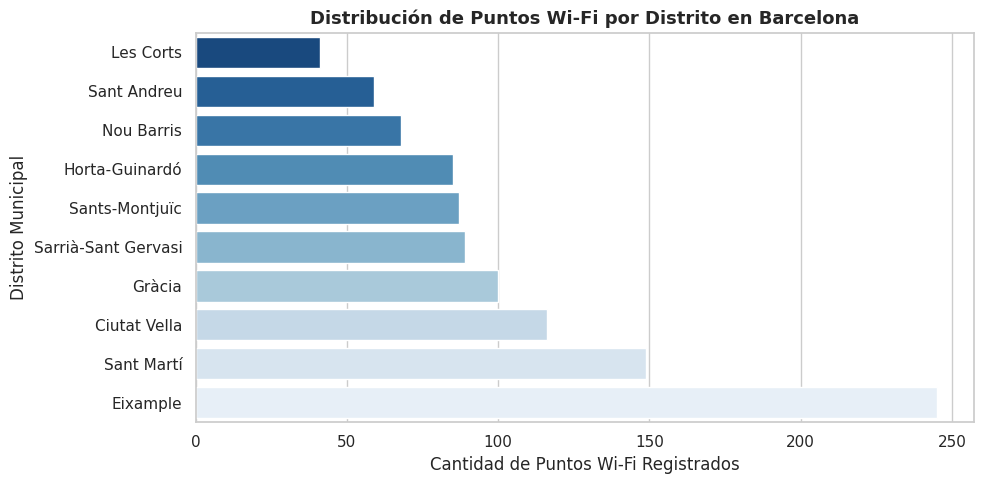

In [37]:
# Configuración del tema visual global
sns.set_theme(style="whitegrid")

# 1. Agrupamos y contamos cuántos puntos hay por distrito
df_distritos = (
    df_limpio.groupby("distrito").size().reset_index(name="cantidad_puntos")
)

# 2. Creamos la figura
plt.figure(figsize=(10, 5))

# Graficamos ordenando de menor a mayor para que el más alto quede arriba
sns.barplot(
    data=df_distritos.sort_values("cantidad_puntos", ascending=True),
    x="cantidad_puntos",
    y="distrito",
    hue="distrito",
    legend=False,
    palette="Blues_r",  # Paleta de degradado azul
)

# Añadimos títulos y etiquetas claras
plt.title(
    "Distribución de Puntos Wi-Fi por Distrito en Barcelona",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Cantidad de Puntos Wi-Fi Registrados")
plt.ylabel("Distrito Municipal")

# Ajustamos márgenes para evitar recortes
plt.tight_layout()
plt.show()

##**Gráfico 2 - Dispersión y Regresión (Scatter Plot)**

### 2. Visualización: Relación entre Renta Media y Cobertura Wi-Fi

**Justificación del gráfico:**
Para analizar la brecha digital, necesitamos observar si existe alguna correlación entre la riqueza económica de un barrio y los recursos tecnológicos públicos de los que dispone. Elegimos un **gráfico de dispersión con línea de tendencia (`sns.regplot`)** porque permite representar dos variables numéricas continuas a la vez (Renta en $€$ vs. Número de puntos Wi-Fi) y evaluar de un vistazo si la pendiente sugiere una desigualdad.

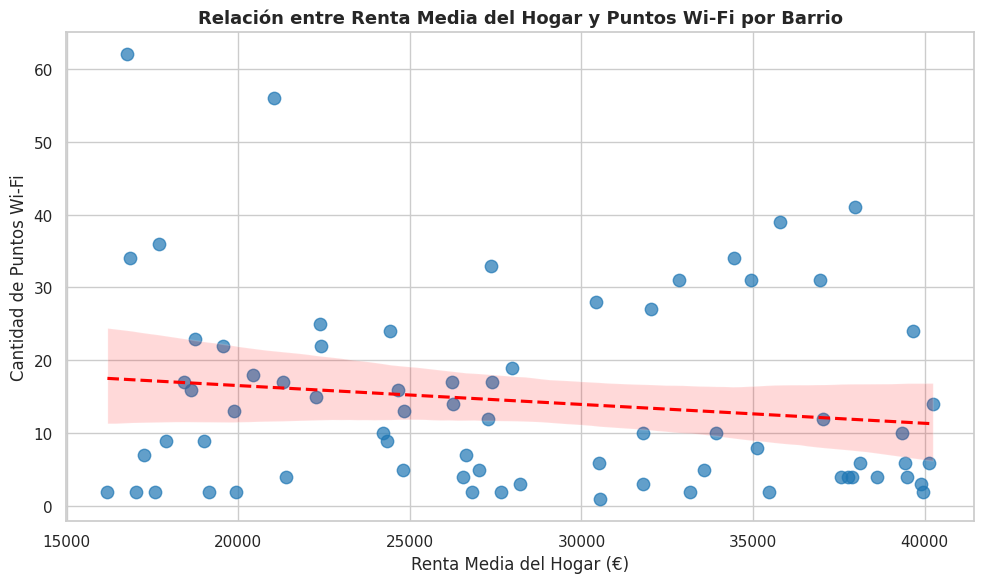

In [38]:
# 1. Agrupamos los puntos por barrio
df_barrio_puntos = (
    df_limpio.groupby("barrio").size().reset_index(name="cantidad_puntos")
)

# 2. Hacemos un merge en Pandas con la tabla socioeconómica
df_comparacion = pd.merge(df_barrio_puntos, df_socio, on="barrio")

# 3. Dibujamos el gráfico de dispersión con línea de tendencia
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_comparacion,
    x="renta_media_hogar",
    y="cantidad_puntos",
    scatter_kws={"alpha": 0.7, "s": 80, "color": "#1f77b4"},  # Transparencia y tamaño de puntos
    line_kws={"color": "red", "linestyle": "--"},             # Línea de tendencia destacada
)

plt.title(
    "Relación entre Renta Media del Hogar y Puntos Wi-Fi por Barrio",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Renta Media del Hogar (€)")
plt.ylabel("Cantidad de Puntos Wi-Fi")

plt.tight_layout()
plt.show()

**CONCLUSIONES**: El gráfico de dispersión nos permite evaluar si la distribución del Wi-Fi público favorece o perjudica a las zonas con menor nivel de ingresos. Si observamos una pendiente descendente o plana, significa que la inversión pública está actuando como un balanceador social. En este caso tenemos una pendiente negativa (la linea cae hacia la derecha) lo que significa que los barrios más humildes tienen más Wi-Fi público. Esto indicaría una política pública enfocada en compensar la falta de recursos privados.

##**Gráfico 3 - Comparativa por Nivel de Vulnerabilidad**

### 3. Visualización: Puntos Wi-Fi según el Nivel de Vulnerabilidad

**Justificación del gráfico:**
Para responder directamente al enfoque social del proyecto, categorizamos la presencia de Wi-Fi agrupada por las etiquetas socioeconómicas ('Baja', 'Media', 'Alta' vulnerabilidad). Un **gráfico de cajas o un gráfico de barras por categoría** nos permite comparar grupos categóricos de forma limpia para identificar qué colectivo territorial requiere mayor inversión.

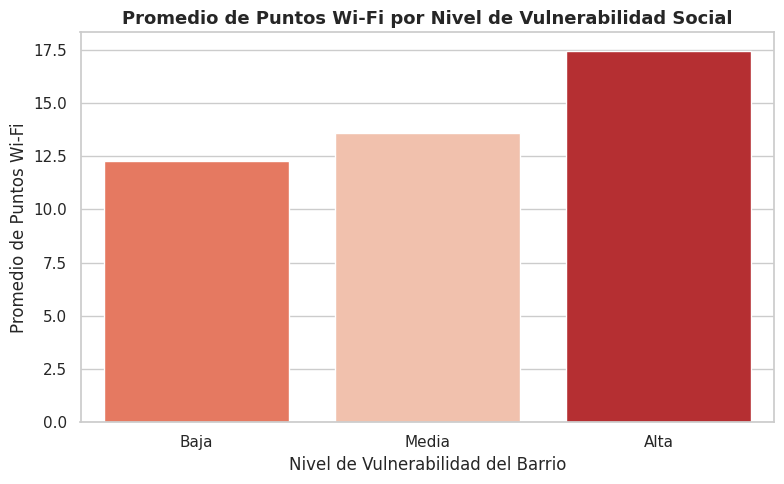

In [39]:
# 1. Calculamos el promedio de puntos Wi-Fi según la vulnerabilidad del barrio
df_vulnerabilidad = (
    df_comparacion.groupby("nivel_vulnerabilidad")["cantidad_puntos"]
    .mean()
    .reset_index()
)

# 2. Graficamos
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_vulnerabilidad,
    x="nivel_vulnerabilidad",
    y="cantidad_puntos",
    hue="nivel_vulnerabilidad",
    legend=False,
    order=["Baja", "Media", "Alta"],  # Ordenamos lógicamente la categoría
    palette="Reds_r",
)

plt.title(
    "Promedio de Puntos Wi-Fi por Nivel de Vulnerabilidad Social",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Nivel de Vulnerabilidad del Barrio")
plt.ylabel("Promedio de Puntos Wi-Fi")

plt.tight_layout()
plt.show()

**CONCLUSIONES:** Este gráfico resume de forma ejecutiva y visual el compromiso social de la red pública. Si la barra de vulnerabilidad 'Alta' presenta el promedio más bajo de puntos de conexión, identificamos una oportunidad clara de intervención pública para reasignar recursos. En este caso la barra 'Alta' es la más alta: Significa que el Ayuntamiento ha instalado conscientemente más puntos en zonas con mayor necesidad socioeconómica para fomentar la inclusión.

## 📢 Storytelling con Datos: Del Análisis a la Decisión

### 1. Conclusiones Clave (en lenguaje no técnico)
* **Distribución Desigual:** Los puntos Wi-Fi públicos no se distribuyen de forma equitativa entre todos los distritos de Barcelona; existe una mayor concentración en distritos centrales con mayor densidad de equipamientos públicos (bibliotecas, centros cívicos).
* **Foco en Barrios Vulnerables:** Existen barrios clasificados con un nivel de vulnerabilidad 'Alta' que cuentan con un número reducido de puntos de conexión (menos de 3 unidades), lo que perpetúa la brecha digital en hogares con menores recursos.

### 2. ¿A quién le sirve esta información?
* **Equipos de Planificación Urbana y Servicios Sociales:** A las administraciones públicas y al Ayuntamiento para orientar las futuras partidas presupuestarias de infraestructura tecnológica hacia los barrios más vulnerables.
* **Entidades Sociales y ONGs:** Organismos que realizan alfabetización digital pueden identificar en qué barrios es más prioritario desplegar aulas móviles de conectividad o reparto de tarjetas SIM.

### 3. Reflexión sobre las Limitaciones del Dato
* **Falta de métricas de calidad:** El dataset únicamente cuenta la *cantidad* de puntos registrados, pero no mide el rendimiento real de la red (velocidad de bajada/subida, ancho de banda o disponibilidad del servicio).
* **Ausencia de densidad poblacional:** No se pondera el número de puntos según la cantidad de habitantes o la superficie del barrio, lo que podría dar una falsa impresión de cobertura en zonas poco pobladas.